# Procurement & Supplier Management
**Student solutions**

## Procurement case
A manufacturer buys **VALVE20, a 20 mm brass valve**, from Suppliers A, B and C. All prices are in EUR per piece. The buyer is reviewing delivery, quality and recorded costs before planning a **9,000-unit July requirement**.

The data are synthetic. There are 60 closed orders per supplier, plus three status records per supplier. The review date is **30 June 2026**. The supplied supplier profile records hypothetical July capacity and qualification status.

Run setup and Baseline first, then Tasks 1–5. Run each task at its BEFORE value, inspect the output, change only the marked setting and run again. Each experiment reads the same source records and starts independently. Answer Notice, Think and Explain using the displayed evidence.


## Measures and their meaning
- **PO:** purchase order. One row is one order for one component. A closed row records its single final receipt; a short receipt closes with the unreceived balance cancelled.
- **Lead time:** calendar days from order to actual receipt. The mean describes average speed; standard deviation describes spread in days.
- **Promised-date OTD:** on-time delivery percentage among closed orders with known receipts. Receipt on the promised date counts as on time. Open and unconfirmed records are shown separately.
- **In full:** received quantity is at least ordered quantity. Timeliness and completeness are separate checks.
- **Flagged-order percentage:** orders containing at least one defective unit / inspected closed orders.
- **Defective-unit percentage:** defective units / inspected units. Every received unit in a closed order is inspected in this case.
- **Recorded procurement cost:** purchase, freight, inspection and rework divided by received units. Rework restores defective units; defects remain recorded as first-inspection failures. No purchase refund is assumed.
- **Qualification:** approval to supply this component. A performance screen then applies the buyer’s stated requirements. Capacity is the assumed available quantity for July.


## Setup
Run the following folded cells. Task settings appear below Baseline.

In [1]:
"""Calculations for the synthetic Hof procurement case."""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
REVIEW_DATE=pd.Timestamp('2026-06-30')


In [2]:
from pathlib import Path
from io import StringIO
import pandas as pd
# Use the supplied files. The identical embedded CSVs also let this notebook run on its own in Colab.
orders_raw = pd.read_csv(Path('data/procurement_orders.csv') if Path('data/procurement_orders.csv').exists() else StringIO('PO_ID,Supplier,Product_Code,Product,Unit,Currency,PO_Date,Promised_Date,Actual_Receipt_Date,Status,Ordered_Qty,Received_Qty,Inspected_Qty,Defective_Qty,Unit_Price_EUR,Freight_EUR,Inspection_Cost_EUR,Rework_Cost_EUR\nA-001,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-02,2026-01-13,2026-01-11,Closed,400,380.0,380.0,6.0,9.0,456.0,114.0,48.0\nA-002,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-04,2026-01-15,2026-01-13,Closed,500,480.0,480.0,6.0,9.0,576.0,144.0,48.0\nA-003,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-06,2026-01-17,2026-01-16,Closed,600,580.0,580.0,6.0,9.0,696.0,174.0,48.0\nA-004,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-08,2026-01-19,2026-01-18,Closed,400,400.0,400.0,6.0,9.0,480.0,120.0,48.0\nA-005,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-10,2026-01-21,2026-01-20,Closed,500,500.0,500.0,6.0,9.0,600.0,150.0,48.0\nA-006,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-12,2026-01-23,2026-01-22,Closed,600,600.0,600.0,6.0,9.0,720.0,180.0,48.0\nA-007,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-14,2026-01-25,2026-01-25,Closed,400,400.0,400.0,6.0,9.0,480.0,120.0,48.0\nA-008,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-16,2026-01-27,2026-01-27,Closed,500,500.0,500.0,6.0,9.0,600.0,150.0,48.0\nA-009,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-18,2026-01-29,2026-01-29,Closed,600,600.0,600.0,6.0,9.0,720.0,180.0,48.0\nA-010,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-20,2026-01-31,2026-02-01,Closed,400,400.0,400.0,6.0,9.0,480.0,120.0,48.0\nA-011,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-22,2026-02-02,2026-01-31,Closed,500,500.0,500.0,6.0,9.0,600.0,150.0,48.0\nA-012,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-24,2026-02-04,2026-02-02,Closed,600,600.0,600.0,6.0,9.0,720.0,180.0,48.0\nA-013,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-26,2026-02-06,2026-02-05,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-014,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-28,2026-02-08,2026-02-07,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-015,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-30,2026-02-10,2026-02-09,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-016,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-01,2026-02-12,2026-02-11,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-017,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-03,2026-02-14,2026-02-14,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-018,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-05,2026-02-16,2026-02-16,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-019,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-07,2026-02-18,2026-02-18,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-020,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-09,2026-02-20,2026-02-21,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-021,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-11,2026-02-22,2026-02-20,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-022,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-13,2026-02-24,2026-02-22,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-023,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-15,2026-02-26,2026-02-25,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-024,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-17,2026-02-28,2026-02-27,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-025,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-19,2026-03-02,2026-03-01,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-026,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-21,2026-03-04,2026-03-03,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-027,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-23,2026-03-06,2026-03-06,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-028,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-25,2026-03-08,2026-03-08,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-029,A,VALVE20,20 mm brass valve,piece,EUR,2026-02-27,2026-03-10,2026-03-10,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-030,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-01,2026-03-12,2026-03-13,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-031,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-03,2026-03-14,2026-03-12,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-032,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-05,2026-03-16,2026-03-14,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-033,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-07,2026-03-18,2026-03-17,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-034,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-09,2026-03-20,2026-03-19,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-035,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-11,2026-03-22,2026-03-21,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-036,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-13,2026-03-24,2026-03-23,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-037,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-15,2026-03-26,2026-03-26,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-038,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-17,2026-03-28,2026-03-28,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-039,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-19,2026-03-30,2026-03-30,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-040,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-21,2026-04-01,2026-04-02,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-041,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-23,2026-04-03,2026-04-01,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-042,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-25,2026-04-05,2026-04-03,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-043,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-27,2026-04-07,2026-04-06,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-044,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-29,2026-04-09,2026-04-08,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-045,A,VALVE20,20 mm brass valve,piece,EUR,2026-03-31,2026-04-11,2026-04-10,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-046,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-02,2026-04-13,2026-04-12,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-047,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-04,2026-04-15,2026-04-15,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-048,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-06,2026-04-17,2026-04-17,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-049,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-08,2026-04-19,2026-04-19,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-050,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-10,2026-04-21,2026-04-22,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-051,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-12,2026-04-23,2026-04-21,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-052,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-14,2026-04-25,2026-04-23,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-053,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-16,2026-04-27,2026-04-26,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-054,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-18,2026-04-29,2026-04-28,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-055,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-20,2026-05-01,2026-04-30,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-056,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-22,2026-05-03,2026-05-02,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-057,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-24,2026-05-05,2026-05-05,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-058,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-26,2026-05-07,2026-05-07,Closed,400,400.0,400.0,0.0,9.0,480.0,120.0,0.0\nA-059,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-28,2026-05-09,2026-05-09,Closed,500,500.0,500.0,0.0,9.0,600.0,150.0,0.0\nA-060,A,VALVE20,20 mm brass valve,piece,EUR,2026-04-30,2026-05-11,2026-05-12,Closed,600,600.0,600.0,0.0,9.0,720.0,180.0,0.0\nA-061,A,VALVE20,20 mm brass valve,piece,EUR,2026-06-01,2026-06-15,,Open,500,,,,9.0,,,\nA-062,A,VALVE20,20 mm brass valve,piece,EUR,2026-06-25,2026-07-08,,Open,500,,,,9.0,,,\nA-063,A,VALVE20,20 mm brass valve,piece,EUR,2026-05-20,2026-06-02,,Receipt_unconfirmed,500,,,,9.0,,,\nB-001,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-02,2026-01-14,2026-01-07,Closed,400,380.0,380.0,30.0,10.0,76.0,38.0,240.0\nB-002,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-04,2026-01-16,2026-01-10,Closed,500,500.0,500.0,30.0,10.0,100.0,50.0,240.0\nB-003,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-06,2026-01-18,2026-01-13,Closed,600,600.0,600.0,30.0,10.0,120.0,60.0,240.0\nB-004,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-08,2026-01-20,2026-01-16,Closed,400,400.0,400.0,30.0,10.0,80.0,40.0,240.0\nB-005,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-10,2026-01-22,2026-01-19,Closed,500,500.0,500.0,30.0,10.0,100.0,50.0,240.0\nB-006,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-12,2026-01-24,2026-01-21,Closed,600,600.0,600.0,30.0,10.0,120.0,60.0,240.0\nB-007,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-14,2026-01-26,2026-01-24,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-008,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-16,2026-01-28,2026-01-27,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-009,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-18,2026-01-30,2026-01-30,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-010,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-20,2026-02-01,2026-02-02,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-011,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-22,2026-02-03,2026-01-27,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-012,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-24,2026-02-05,2026-01-30,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-013,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-26,2026-02-07,2026-02-02,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-014,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-28,2026-02-09,2026-02-05,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-015,B,VALVE20,20 mm brass valve,piece,EUR,2026-01-30,2026-02-11,2026-02-08,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-016,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-01,2026-02-13,2026-02-10,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-017,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-03,2026-02-15,2026-02-13,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-018,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-05,2026-02-17,2026-02-16,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-019,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-07,2026-02-19,2026-02-19,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-020,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-09,2026-02-21,2026-02-22,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-021,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-11,2026-02-23,2026-02-16,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-022,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-13,2026-02-25,2026-02-19,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-023,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-15,2026-02-27,2026-02-22,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-024,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-17,2026-03-01,2026-02-25,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-025,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-19,2026-03-03,2026-02-28,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-026,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-21,2026-03-05,2026-03-02,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-027,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-23,2026-03-07,2026-03-05,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-028,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-25,2026-03-09,2026-03-08,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-029,B,VALVE20,20 mm brass valve,piece,EUR,2026-02-27,2026-03-11,2026-03-11,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-030,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-01,2026-03-13,2026-03-14,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-031,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-03,2026-03-15,2026-03-08,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-032,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-05,2026-03-17,2026-03-11,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-033,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-07,2026-03-19,2026-03-14,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-034,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-09,2026-03-21,2026-03-17,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-035,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-11,2026-03-23,2026-03-20,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-036,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-13,2026-03-25,2026-03-22,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-037,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-15,2026-03-27,2026-03-25,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-038,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-17,2026-03-29,2026-03-28,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-039,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-19,2026-03-31,2026-03-31,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-040,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-21,2026-04-02,2026-04-03,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-041,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-23,2026-04-04,2026-03-28,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-042,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-25,2026-04-06,2026-03-31,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-043,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-27,2026-04-08,2026-04-03,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-044,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-29,2026-04-10,2026-04-06,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-045,B,VALVE20,20 mm brass valve,piece,EUR,2026-03-31,2026-04-12,2026-04-09,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-046,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-02,2026-04-14,2026-04-11,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-047,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-04,2026-04-16,2026-04-14,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-048,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-06,2026-04-18,2026-04-17,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-049,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-08,2026-04-20,2026-04-20,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-050,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-10,2026-04-22,2026-04-23,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-051,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-12,2026-04-24,2026-04-17,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-052,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-14,2026-04-26,2026-04-20,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-053,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-16,2026-04-28,2026-04-23,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-054,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-18,2026-04-30,2026-04-26,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-055,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-20,2026-05-02,2026-04-29,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-056,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-22,2026-05-04,2026-05-01,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-057,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-24,2026-05-06,2026-05-04,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-058,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-26,2026-05-08,2026-05-07,Closed,400,400.0,400.0,0.0,10.0,80.0,40.0,0.0\nB-059,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-28,2026-05-10,2026-05-10,Closed,500,500.0,500.0,0.0,10.0,100.0,50.0,0.0\nB-060,B,VALVE20,20 mm brass valve,piece,EUR,2026-04-30,2026-05-12,2026-05-13,Closed,600,600.0,600.0,0.0,10.0,120.0,60.0,0.0\nB-061,B,VALVE20,20 mm brass valve,piece,EUR,2026-06-01,2026-06-15,,Open,500,,,,10.0,,,\nB-062,B,VALVE20,20 mm brass valve,piece,EUR,2026-06-25,2026-07-08,,Open,500,,,,10.0,,,\nB-063,B,VALVE20,20 mm brass valve,piece,EUR,2026-05-20,2026-06-02,,Receipt_unconfirmed,500,,,,10.0,,,\nC-001,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-02,2026-01-12,2026-01-09,Closed,400,380.0,380.0,20.0,9.5,228.0,76.0,160.0\nC-002,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-04,2026-01-14,2026-01-12,Closed,500,480.0,480.0,20.0,9.5,288.0,96.0,160.0\nC-003,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-06,2026-01-16,2026-01-15,Closed,600,580.0,580.0,20.0,9.5,348.0,116.0,160.0\nC-004,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-08,2026-01-18,2026-01-18,Closed,400,380.0,380.0,20.0,9.5,228.0,76.0,160.0\nC-005,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-10,2026-01-20,2026-01-20,Closed,500,480.0,480.0,20.0,9.5,288.0,96.0,160.0\nC-006,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-12,2026-01-22,2026-01-23,Closed,600,580.0,580.0,20.0,9.5,348.0,116.0,160.0\nC-007,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-14,2026-01-24,2026-01-26,Closed,400,400.0,400.0,20.0,9.5,240.0,80.0,160.0\nC-008,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-16,2026-01-26,2026-01-29,Closed,500,500.0,500.0,20.0,9.5,300.0,100.0,160.0\nC-009,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-18,2026-01-28,2026-02-01,Closed,600,600.0,600.0,20.0,9.5,360.0,120.0,160.0\nC-010,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-20,2026-01-30,2026-02-05,Closed,400,400.0,400.0,20.0,9.5,240.0,80.0,160.0\nC-011,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-22,2026-02-01,2026-01-29,Closed,500,500.0,500.0,20.0,9.5,300.0,100.0,160.0\nC-012,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-24,2026-02-03,2026-02-01,Closed,600,600.0,600.0,20.0,9.5,360.0,120.0,160.0\nC-013,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-26,2026-02-05,2026-02-04,Closed,400,400.0,400.0,20.0,9.5,240.0,80.0,160.0\nC-014,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-28,2026-02-07,2026-02-07,Closed,500,500.0,500.0,20.0,9.5,300.0,100.0,160.0\nC-015,C,VALVE20,20 mm brass valve,piece,EUR,2026-01-30,2026-02-09,2026-02-09,Closed,600,600.0,600.0,20.0,9.5,360.0,120.0,160.0\nC-016,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-01,2026-02-11,2026-02-12,Closed,400,400.0,400.0,20.0,9.5,240.0,80.0,160.0\nC-017,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-03,2026-02-13,2026-02-15,Closed,500,500.0,500.0,20.0,9.5,300.0,100.0,160.0\nC-018,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-05,2026-02-15,2026-02-18,Closed,600,600.0,600.0,20.0,9.5,360.0,120.0,160.0\nC-019,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-07,2026-02-17,2026-02-21,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-020,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-09,2026-02-19,2026-02-25,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-021,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-11,2026-02-21,2026-02-18,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-022,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-13,2026-02-23,2026-02-21,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-023,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-15,2026-02-25,2026-02-24,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-024,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-17,2026-02-27,2026-02-27,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-025,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-19,2026-03-01,2026-03-01,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-026,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-21,2026-03-03,2026-03-04,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-027,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-23,2026-03-05,2026-03-07,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-028,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-25,2026-03-07,2026-03-10,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-029,C,VALVE20,20 mm brass valve,piece,EUR,2026-02-27,2026-03-09,2026-03-13,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-030,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-01,2026-03-11,2026-03-17,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-031,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-03,2026-03-13,2026-03-10,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-032,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-05,2026-03-15,2026-03-13,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-033,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-07,2026-03-17,2026-03-16,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-034,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-09,2026-03-19,2026-03-19,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-035,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-11,2026-03-21,2026-03-21,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-036,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-13,2026-03-23,2026-03-24,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-037,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-15,2026-03-25,2026-03-27,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-038,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-17,2026-03-27,2026-03-30,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-039,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-19,2026-03-29,2026-04-02,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-040,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-21,2026-03-31,2026-04-06,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-041,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-23,2026-04-02,2026-03-30,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-042,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-25,2026-04-04,2026-04-02,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-043,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-27,2026-04-06,2026-04-05,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-044,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-29,2026-04-08,2026-04-08,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-045,C,VALVE20,20 mm brass valve,piece,EUR,2026-03-31,2026-04-10,2026-04-10,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-046,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-02,2026-04-12,2026-04-13,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-047,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-04,2026-04-14,2026-04-16,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-048,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-06,2026-04-16,2026-04-19,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-049,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-08,2026-04-18,2026-04-22,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-050,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-10,2026-04-20,2026-04-26,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-051,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-12,2026-04-22,2026-04-19,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-052,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-14,2026-04-24,2026-04-22,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-053,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-16,2026-04-26,2026-04-25,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-054,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-18,2026-04-28,2026-04-28,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-055,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-20,2026-04-30,2026-04-30,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-056,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-22,2026-05-02,2026-05-03,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-057,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-24,2026-05-04,2026-05-06,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-058,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-26,2026-05-06,2026-05-09,Closed,400,400.0,400.0,0.0,9.5,240.0,80.0,0.0\nC-059,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-28,2026-05-08,2026-05-12,Closed,500,500.0,500.0,0.0,9.5,300.0,100.0,0.0\nC-060,C,VALVE20,20 mm brass valve,piece,EUR,2026-04-30,2026-05-10,2026-05-16,Closed,600,600.0,600.0,0.0,9.5,360.0,120.0,0.0\nC-061,C,VALVE20,20 mm brass valve,piece,EUR,2026-06-01,2026-06-15,,Open,500,,,,9.5,,,\nC-062,C,VALVE20,20 mm brass valve,piece,EUR,2026-06-25,2026-07-08,,Open,500,,,,9.5,,,\nC-063,C,VALVE20,20 mm brass valve,piece,EUR,2026-05-20,2026-06-02,,Receipt_unconfirmed,500,,,,9.5,,,\n'))
suppliers = pd.read_csv(Path('data/supplier_profile.csv') if Path('data/supplier_profile.csv').exists() else StringIO('Supplier,Qualification,Available_Capacity_July_units\nA,Approved,8000\nB,Approved,6000\nC,Conditional,12000\n'))


In [3]:
def prepare(orders):
    d=orders.copy()
    for col in ['PO_Date','Promised_Date','Actual_Receipt_Date']:
        d[col]=pd.to_datetime(d[col],errors='raise')
    d['Lead_Days']=(d.Actual_Receipt_Date-d.PO_Date).dt.days
    d['Days_After_Promise']=(d.Actual_Receipt_Date-d.Promised_Date).dt.days
    return d

In [4]:
def completed(orders):
    return orders.loc[orders.Status.eq('Closed') & orders.Actual_Receipt_Date.notna()].copy()

In [5]:
def supplier_metrics(orders):
    rows=[]
    for supplier,g in completed(orders).groupby('Supplier'):
        received=g.Received_Qty.sum();inspected=g.Inspected_Qty.sum()
        purchase=(g.Received_Qty*g.Unit_Price_EUR).sum()
        extra=g[['Freight_EUR','Inspection_Cost_EUR','Rework_Cost_EUR']].sum().sum()
        rows.append({'Supplier':supplier,'Completed POs':len(g),'Mean days':g.Lead_Days.mean(),
          'Std days':g.Lead_Days.std(ddof=1),'Promised-date OTD %':g.Days_After_Promise.le(0).mean()*100,
          'In-full %':g.Received_Qty.ge(g.Ordered_Qty).mean()*100,
          'Flagged POs':int(g.Defective_Qty.gt(0).sum()),'Flagged PO %':g.Defective_Qty.gt(0).mean()*100,
          'Inspected units':int(inspected),'Defective units':int(g.Defective_Qty.sum()),
          'Defective unit %':g.Defective_Qty.sum()/inspected*100,
          'Purchase EUR/unit':purchase/received,'Recorded cost EUR/unit':(purchase+extra)/received})
    return pd.DataFrame(rows).set_index('Supplier')

In [6]:
def baseline(orders,profiles):
    display(orders.head(3));display(profiles)
    print('Review date: 30 June 2026. Synthetic case: VALVE20, 20 mm brass valve, pieces, EUR.')
    table=orders.groupby(['Supplier','Status']).size().unstack(fill_value=0);display(table)
    open_orders=orders[orders.Status.eq('Open')]
    print(f'Open overdue: {int(open_orders.Promised_Date.lt(REVIEW_DATE).sum())}; open not yet due: {int(open_orders.Promised_Date.ge(REVIEW_DATE).sum())}; receipt unconfirmed: {int(orders.Status.eq("Receipt_unconfirmed").sum())}.')
    print('The completed-order scorecard uses 60 orders per supplier. Open and unconfirmed orders remain in this separate status view.')

In [7]:
def show_delivery(orders,supplier='A'):
    if supplier not in ['A','B']:raise ValueError('Choose A or B.')
    g=completed(orders);m=supplier_metrics(orders)
    display(m.loc[['A','B'],['Completed POs','Mean days','Std days']].round(2))
    fig,ax=plt.subplots(figsize=(8,3));vals=g.loc[g.Supplier.eq(supplier),'Lead_Days']
    ax.hist(vals,bins=np.arange(4.5,14.6,1),color='#5B9BD5',edgecolor='white');ax.set(xlabel='Calendar days from order to receipt',ylabel='Completed orders',title=f'Supplier {supplier}: 60 completed orders',xlim=(4.5,14.5),ylim=(0,26));plt.tight_layout();plt.show()
    print('Both runs use the same date range and fixed plot scales. Standard deviation summarises spread around the mean in days.')
    return m.loc[supplier]

In [8]:
def show_target(orders,target_days=10):
    if target_days not in [10,12]:raise ValueError('Choose 10 or 12 days.')
    g=completed(orders);m=supplier_metrics(orders)
    count=g.groupby('Supplier').Lead_Days.apply(lambda x:int(x.le(target_days).sum()))
    result=pd.DataFrame({'Completed POs':m['Completed POs'],'Within internal target':count,'Within target %':count/m['Completed POs']*100,'Promised-date OTD %':m['Promised-date OTD %']})
    display(result.round(2));result[['Within target %','Promised-date OTD %']].plot.bar(figsize=(8,3),ylim=(0,100),color=['#5B9BD5','#ED7D31']);plt.ylabel('Completed orders (%)');plt.title(f'Internal target: {target_days} calendar days');plt.xticks(rotation=0);plt.tight_layout();plt.show()
    print('The internal target is a hypothetical reporting rule. Original promised dates and actual receipts stay unchanged.')
    return result

In [9]:
def show_quality(orders,view='orders'):
    if view not in ['orders','units']:raise ValueError('Choose orders or units.')
    m=supplier_metrics(orders);display(m[['Completed POs','Flagged POs','Flagged PO %','Inspected units','Defective units','Defective unit %']].round(2))
    col='Flagged PO %' if view=='orders' else 'Defective unit %'
    m[col].plot.bar(figsize=(7,3),color='#5B9BD5',ylim=(0,35 if view=='orders' else 1.4));plt.ylabel(col);plt.title('Orders with any defect' if view=='orders' else 'Defective units among inspected units');plt.xticks(rotation=0);plt.tight_layout();plt.show()
    print('All received units in the closed orders were inspected. A flagged order may contain one or many defective units. Read the axis: the two charts use different scales.')
    return m

In [10]:
def show_cost(orders,basis='purchase'):
    if basis not in ['purchase','recorded']:raise ValueError('Choose purchase or recorded.')
    m=supplier_metrics(orders);display(m[['Purchase EUR/unit','Recorded cost EUR/unit']].round(3))
    col='Purchase EUR/unit' if basis=='purchase' else 'Recorded cost EUR/unit'
    m[col].plot.bar(figsize=(7,3),color='#5B9BD5',ylim=(0,12));plt.ylabel('EUR per received unit');plt.title('Purchase price' if basis=='purchase' else 'Recorded procurement cost');plt.xticks(rotation=0);plt.tight_layout();plt.show()
    print('Recorded cost = purchase + freight + inspection + rework, divided by received units. These case records exclude downtime, financing, administration and later lifecycle costs.')
    return m

In [11]:
def screen_suppliers(orders,profiles,max_defective_pct=1.0):
    if max_defective_pct not in [1.0,.5]:raise ValueError('Choose 1.0 or 0.5 percent.')
    m=supplier_metrics(orders).join(profiles.set_index('Supplier'))
    m['Approved']=m.Qualification.eq('Approved');m['Delivery passes']=m['Promised-date OTD %'].ge(85);m['Quality passes']=m['Defective unit %'].le(max_defective_pct)
    m['Eligible']=m[['Approved','Delivery passes','Quality passes']].all(axis=1)
    display(m[['Qualification','Promised-date OTD %','Defective unit %','Available_Capacity_July_units','Delivery passes','Quality passes','Eligible']].round(2))
    capacity=int(m.loc[m.Eligible,'Available_Capacity_July_units'].sum());need=9000
    print(f'July requirement: {need:,} units. Eligible capacity: {capacity:,}. Capacity gap: {max(0,need-capacity):,}.')
    print('Hypothetical buyer rules: Approved, promised-date OTD at least 85%, and the chosen defective-unit ceiling. Capacity is assumed available for July, not an allocation recommendation.')
    print('A follow-up should identify the failed criterion, request evidence and agree a measurable review. Changing a rule does not improve a supplier.')
    return m

## Baseline
Read the first records and the order-status counts. A blank receipt date is interpreted together with the order status.

In [12]:
orders = prepare(orders_raw)
baseline(orders, suppliers)

,PO_ID,Supplier,Product_Code,Product,Unit,Currency,PO_Date,Promised_Date,Actual_Receipt_Date,Status,Ordered_Qty,Received_Qty,Inspected_Qty,Defective_Qty,Unit_Price_EUR,Freight_EUR,Inspection_Cost_EUR,Rework_Cost_EUR,Lead_Days,Days_After_Promise
0,A-001,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-02,2026-01-13,2026-01-11,Closed,400,380.0,380.0,6.0,9.0,456.0,114.0,48.0,9.0,-2.0
1,A-002,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-04,2026-01-15,2026-01-13,Closed,500,480.0,480.0,6.0,9.0,576.0,144.0,48.0,9.0,-2.0
2,A-003,A,VALVE20,20 mm brass valve,piece,EUR,2026-01-06,2026-01-17,2026-01-16,Closed,600,580.0,580.0,6.0,9.0,696.0,174.0,48.0,10.0,-1.0


,Supplier,Qualification,Available_Capacity_July_units
0,A,Approved,8000
1,B,Approved,6000
2,C,Conditional,12000


Review date: 30 June 2026. Synthetic case: VALVE20, 20 mm brass valve, pieces, EUR.


Status,Closed,Open,Receipt_unconfirmed
Supplier,,,
A,60,2,1
B,60,2,1
C,60,2,1


Open overdue: 3; open not yet due: 3; receipt unconfirmed: 3.
The completed-order scorecard uses 60 orders per supplier. Open and unconfirmed orders remain in this separate status view.


**First record:** A-001 orders 400 VALVE20 units on 2 January. Supplier A promises 13 January and delivers 380 units on 11 January. All 380 are inspected; 6 initially fail inspection and are reworked. The order arrives on time but 20 units short. Purchase price is EUR 9.00 per received unit.

## 1. Compare delivery speed and spread

**BEFORE:** Run Supplier A. Read its mean, spread and delivery-time histogram.

**CHANGE:** Change SUPPLIER from A to B. Keep the same completed orders and date range.

**AFTER:** Compare the histograms using their fixed axes and the two supplier rows.

,Completed POs,Mean days,Std days
Supplier,,,
A,60,10.3,0.91
B,60,9.0,2.47


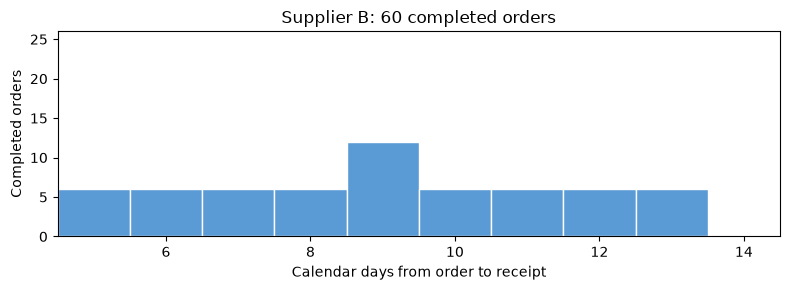

Both runs use the same date range and fixed plot scales. Standard deviation summarises spread around the mean in days.


In [13]:
SUPPLIER = 'B'  # <-- CHANGE HERE: 'A' -> 'B'
result_1 = show_delivery(orders, supplier=SUPPLIER)  # <-- READ OUTPUT

**THINK**

1. **Notice:** Which supplier is faster on average, and which has a wider spread of delivery times?

2. **Think:** A buyer says, “B arrives faster, so its timing is more predictable.” Do both parts follow from these outputs?

3. **Explain:** Explain the difference between speed and consistency to the buyer using one value for each.

**Answers and explanations**

1. B is faster: 9.0 days on average versus 10.3 for A. B has wider spread: standard deviation 2.47 days versus 0.91 for A.

2. Only the speed claim is supported. B ranges from 5 to 13 days while A ranges from 9 to 12. The larger spread makes B less consistent in this case.

3. “B averages 9.0 days, but its timing varies more: spread is 2.47 days versus A’s 0.91. We should discuss both average speed and consistency when reviewing delivery performance.”

## 2. Read delivery performance against a target

**BEFORE:** Use the internal target of 10 days. Read the target percentage and promised-date OTD.

**CHANGE:** Change TARGET_DAYS from 10 to 12. Original promises and actual receipts stay fixed.

**AFTER:** Compare the internal-target bars with the promised-date bars.

,Completed POs,Within internal target,Within target %,Promised-date OTD %
Supplier,,,,
A,60,60,100.0,90.0
B,60,54,90.0,90.0
C,60,42,70.0,50.0


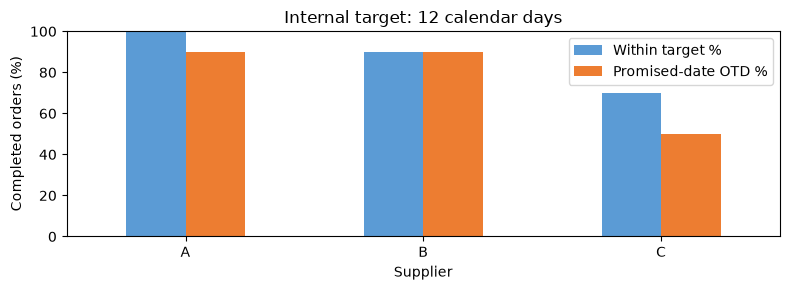

The internal target is a hypothetical reporting rule. Original promised dates and actual receipts stay unchanged.


In [14]:
TARGET_DAYS = 12  # <-- CHANGE HERE: 10 -> 12
result_2 = show_target(orders, target_days=TARGET_DAYS)  # <-- READ OUTPUT

**THINK**

1. **Notice:** Which percentages change when the internal target moves from 10 to 12 days?

2. **Think:** The reported target percentage improves. Have any suppliers actually delivered sooner?

3. **Explain:** A colleague wants to tell management that delivery performance improved. Explain what this run really changed.

**Answers and explanations**

1. Within-target percentages change: A 60% to 100%, B 70% to 90%, C 50% to 70%. Promised-date OTD stays A 90%, B 90%, C 50%.

2. No receipt dates change. More existing deliveries fit a more generous internal target.

3. “We changed the internal target from 10 to 12 days, so more orders meet it. Delivery dates and performance against the original promised dates have not changed.”

## 3. Compare two quality measures

**BEFORE:** Read the percentage of completed orders containing any defective unit.

**CHANGE:** Change QUALITY_VIEW from orders to units.

**AFTER:** Read both denominators in the table and compare the A/B ranking. The chart scale changes with the measure.

,Completed POs,Flagged POs,Flagged PO %,Inspected units,Defective units,Defective unit %
Supplier,,,,,,
A,60,12,20.0,29940,72,0.24
B,60,6,10.0,29980,180,0.60
C,60,18,30.0,29880,360,1.20


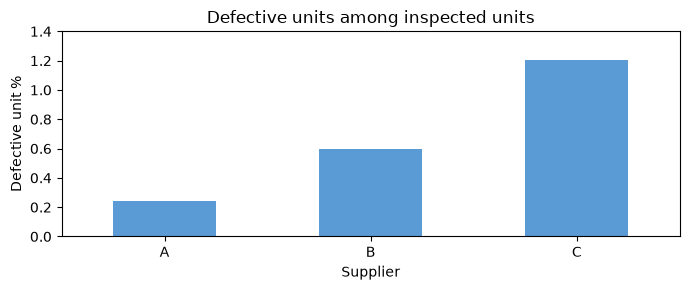

All received units in the closed orders were inspected. A flagged order may contain one or many defective units. Read the axis: the two charts use different scales.


In [15]:
QUALITY_VIEW = 'units'  # <-- CHANGE HERE: 'orders' -> 'units'
result_3 = show_quality(orders, view=QUALITY_VIEW)  # <-- READ OUTPUT

**THINK**

1. **Notice:** Compare A and B: which has fewer flagged orders, and which has the lower defective-unit percentage?

2. **Think:** Why can B have fewer flagged orders but a larger defective-unit percentage? Use the counts in the table.

3. **Explain:** A manager calls B “better quality” using only flagged orders. Explain what the second measure adds.

**Answers and explanations**

1. B has 6/60 flagged orders (10%) versus A’s 12/60 (20%). A has the lower defective-unit percentage: 72/29,940 = 0.2405%, versus B’s 180/29,980 = 0.6004%.

2. B has fewer affected orders, but more defective units within those affected orders. Order incidence and the proportion of units defective answer different questions.

3. “B has quality incidents on fewer orders, but those incidents contain more defective units overall. We should report both the frequency of affected orders and the defective-unit percentage.”

## 4. Compare purchase price and recorded cost

**BEFORE:** Compare purchase prices for the same VALVE20 component in EUR per piece.

**CHANGE:** Change COST_BASIS from purchase to recorded.

**AFTER:** Compare purchase-only and recorded procurement cost per received unit.

,Purchase EUR/unit,Recorded cost EUR/unit
Supplier,,
A,9.0,10.519
B,10.0,10.348
C,9.5,10.396


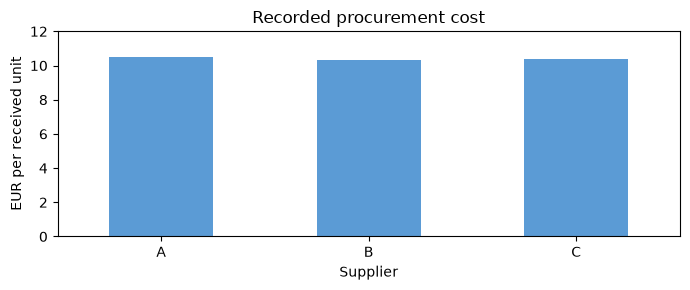

Recorded cost = purchase + freight + inspection + rework, divided by received units. These case records exclude downtime, financing, administration and later lifecycle costs.


In [16]:
COST_BASIS = 'recorded'  # <-- CHANGE HERE: 'purchase' -> 'recorded'
result_4 = show_cost(orders, basis=COST_BASIS)  # <-- READ OUTPUT

**THINK**

1. **Notice:** Which supplier has the lowest purchase price? Which has the lowest recorded cost per received unit?

2. **Think:** What included costs explain why the ranking changes?

3. **Explain:** A colleague says the cheapest quoted supplier must cost the least overall. Explain what the cost table supports and one cost it still leaves out.

**Answers and explanations**

1. A has the lowest purchase price at EUR 9.00. B has the lowest recorded cost at EUR 10.348/unit, versus A 10.519 and C 10.396.

2. Recorded cost adds freight, inspection and rework. A’s low price is offset by higher freight and inspection costs in this synthetic case.

3. “A has the lowest purchase price, while B has the lowest cost across the recorded categories. We have not included downtime, financing, administration or later lifecycle costs, so this is not a complete total-cost-of-ownership comparison.”

## 5. Screen suppliers and check capacity

**BEFORE:** Apply the 1.0% defective-unit ceiling, Approved status and at least 85% promised-date OTD. July need is 9,000 units.

**CHANGE:** Change MAX_DEFECTIVE_PCT from 1.0 to 0.5. Keep all other rules and capacity figures fixed.

**AFTER:** Read each pass/fail column, the eligible suppliers and total available July capacity.

In [17]:
MAX_DEFECTIVE_PCT = 0.5  # <-- CHANGE HERE: 1.0 -> 0.5
result_5 = screen_suppliers(orders, suppliers, max_defective_pct=MAX_DEFECTIVE_PCT)  # <-- READ OUTPUT

,Qualification,Promised-date OTD %,Defective unit %,Available_Capacity_July_units,Delivery passes,Quality passes,Eligible
Supplier,,,,,,,
A,Approved,90.0,0.24,8000,True,True,True
B,Approved,90.0,0.60,6000,True,False,False
C,Conditional,50.0,1.20,12000,False,False,False


July requirement: 9,000 units. Eligible capacity: 8,000. Capacity gap: 1,000.
Hypothetical buyer rules: Approved, promised-date OTD at least 85%, and the chosen defective-unit ceiling. Capacity is assumed available for July, not an allocation recommendation.
A follow-up should identify the failed criterion, request evidence and agree a measurable review. Changing a rule does not improve a supplier.


**THINK**

1. **Notice:** Which suppliers qualify in each run, and what happens to capacity relative to the July requirement?

2. **Think:** Did the stricter quality ceiling change supplier quality or the buyer’s acceptance rule?

3. **Explain:** Write a two-sentence follow-up for procurement: explain why B drops out, what to review with B, and why the remaining shortlist cannot cover July on its own.

**Answers and explanations**

1. At 1.0%, A and B qualify with 14,000 units of combined capacity. At 0.5%, only A qualifies with 8,000 units, leaving a 1,000-unit gap against July’s 9,000-unit requirement. C fails qualification, delivery and quality in both runs.

2. Only the acceptance rule changes. B remains at 0.6004% defective units. Historical quality and available capacity are unchanged.

3. “B exceeds the stricter 0.5% ceiling, so procurement should review the defect records, agree a corrective action and track its defective-unit percentage. A alone offers 8,000 units against a need of 9,000, so the buyer must resolve the 1,000-unit gap before committing the sourcing plan.”

## Supplier review record
Record the product, period, measure and denominator beside each finding. A supplier follow-up states the issue, the evidence requested, the agreed action and the next review measure.

The purchasing plan passes expected receipt dates, quantities and reliability information to inventory planning.